# InceptionTime for PTB-XL MI Detection

In [2]:
from __future__ import annotations
import json, random
from pathlib import Path
from typing import Any
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import wfdb
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, matthews_corrcoef,
    precision_score, recall_score, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay,
)
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## Step 1: Paths, labels, and split checks

In [3]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

LABELS_PATH = PROJECT_ROOT / "data" / "processed" / "ptbxl_labels.csv"
PTBXL_ROOT = PROJECT_ROOT / "data" / "raw" / "ptb-xl"
# If needed, replace the paths above with absolute Windows paths, e.g.
# LABELS_PATH = Path(r"C:\\Users\\YourName\\...\\ptbxl_labels.csv")
# PTBXL_ROOT = Path(r"C:\\Users\\YourName\\...\\ptb-xl")

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results" / "inceptiontime"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE, EPOCHS, NUM_WORKERS = 32, 30, 0
LEARNING_RATE, WEIGHT_DECAY, PATIENCE = 1e-3, 1e-4, 7
FS, N_LEADS, N_SAMPLES = 500, 12, 5000

if not LABELS_PATH.is_file():
    raise FileNotFoundError(f"Label CSV not found: {LABELS_PATH}. Edit LABELS_PATH.")
labels = pd.read_csv(LABELS_PATH)
if "ecg_id" not in labels.columns:
    unnamed = [c for c in labels.columns if str(c).startswith("Unnamed:")]
    if not unnamed:
        raise ValueError(f"ecg_id missing. Columns: {labels.columns.tolist()}")
    labels = labels.rename(columns={unnamed[0]: "ecg_id"})
labels["ecg_id"] = pd.to_numeric(labels["ecg_id"], errors="raise").astype(int)
labels = labels.set_index("ecg_id")

required = {"patient_id", "mi_label", "dataset_split"}
missing = required - set(labels.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

if "filename_hr" not in labels.columns:
    candidates = [
        PTBXL_ROOT / "ptbxl_database.csv",
        PROJECT_ROOT / "data" / "ptb-xl" / "ptbxl_database.csv",
        PROJECT_ROOT / "data" / "raw" / "ptbxl_database.csv",
    ]
    metadata_path = next((p for p in candidates if p.is_file()), None)
    if metadata_path is None:
        raise FileNotFoundError(
            "ptbxl_database.csv not found. Set PTBXL_ROOT to its containing folder."
        )
    metadata = pd.read_csv(metadata_path)
    if not {"ecg_id", "filename_hr"}.issubset(metadata.columns):
        raise ValueError("ptbxl_database.csv must contain ecg_id and filename_hr.")
    metadata["ecg_id"] = pd.to_numeric(metadata["ecg_id"], errors="raise").astype(int)
    lookup = metadata.set_index("ecg_id")["filename_hr"]
    labels["filename_hr"] = labels.index.to_series().map(lookup)
    if labels["filename_hr"].isna().any():
        bad = labels.index[labels["filename_hr"].isna()].tolist()[:10]
        raise ValueError(f"No filename_hr found for ecg_id values: {bad}")
    print("Restored filename_hr from:", metadata_path)

labels["mi_label"] = pd.to_numeric(labels["mi_label"], errors="raise").astype(int)
if not set(labels["mi_label"].unique()).issubset({0, 1}):
    raise ValueError("mi_label must contain only 0 and 1.")

def get_split(name: str) -> pd.DataFrame:
    frame = labels[labels["dataset_split"].astype(str).str.lower() == name].copy()
    if frame.empty:
        raise ValueError(
            f"Split '{name}' not found. Values: {labels['dataset_split'].unique().tolist()}"
        )
    return frame

train_df, val_df, test_df = (
    get_split("train"), get_split("validation"), get_split("test")
)
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(test_df["patient_id"])
assert train_patients.isdisjoint(val_patients), "Train/validation patient leakage"
assert train_patients.isdisjoint(test_patients), "Train/test patient leakage"
assert val_patients.isdisjoint(test_patients), "Validation/test patient leakage"
print("Records:", len(train_df), len(val_df), len(test_df))
print("Patient-level split checks passed.")

Restored filename_hr from: c:\Users\sintu\Desktop\Myocardial Infarction\data\raw\ptb-xl\ptbxl_database.csv
Records: 17418 2183 2198
Patient-level split checks passed.


## Step 2: ECG Dataset and DataLoaders

In [4]:
def resolve_record_path(filename: str) -> Path:
    relative = Path(filename)
    candidates = [
        PTBXL_ROOT / relative,
        PTBXL_ROOT / "records500" / relative,
        PROJECT_ROOT / "data" / "raw" / relative,
    ]
    for path in candidates:
        if path.with_suffix(".hea").is_file():
            return path
    raise FileNotFoundError(
        f"WFDB header not found for {filename}; check PTBXL_ROOT={PTBXL_ROOT}"
    )

class PTBXLMIDataset(Dataset):
    def __init__(self, frame: pd.DataFrame) -> None:
        self.frame = frame.copy()

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int):
        row = self.frame.iloc[index]
        path = resolve_record_path(str(row["filename_hr"]))
        signal, fields = wfdb.rdsamp(str(path))
        if int(fields["fs"]) != FS:
            raise ValueError(f"Expected {FS} Hz, found {fields['fs']} Hz: {path}")
        if signal.shape != (N_SAMPLES, N_LEADS):
            raise ValueError(f"Expected {(N_SAMPLES, N_LEADS)}, got {signal.shape}")
        return (
            torch.tensor(signal.T, dtype=torch.float32),
            torch.tensor(float(row["mi_label"]), dtype=torch.float32),
        )

train_loader = DataLoader(
    PTBXLMIDataset(train_df), batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    PTBXLMIDataset(val_df), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    PTBXLMIDataset(test_df), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
sample_x, sample_y = next(iter(train_loader))
assert sample_x.shape[1:] == (N_LEADS, N_SAMPLES)
print("Batch:", tuple(sample_x.shape), "Targets:", tuple(sample_y.shape))

Batch: (32, 12, 5000) Targets: (32,)


## Step 3: InceptionTime architecture

In [5]:
class InceptionModule1D(nn.Module):
    def __init__(
        self, in_channels: int, out_channels: int = 32,
        bottleneck_channels: int = 32,
        kernel_sizes: tuple[int, ...] = (39, 19, 9),
    ) -> None:
        super().__init__()
        if any(k % 2 == 0 for k in kernel_sizes):
            raise ValueError("Kernel sizes must be odd.")
        self.bottleneck = (
            nn.Conv1d(in_channels, bottleneck_channels, 1, bias=False)
            if in_channels > 1 else nn.Identity()
        )
        branch_channels = bottleneck_channels if in_channels > 1 else in_channels
        self.conv_branches = nn.ModuleList([
            nn.Conv1d(branch_channels, out_channels, k, padding=k // 2, bias=False)
            for k in kernel_sizes
        ])
        self.pool_branch = nn.Sequential(
            nn.MaxPool1d(3, stride=1, padding=1),
            nn.Conv1d(in_channels, out_channels, 1, bias=False),
        )
        self.bn = nn.BatchNorm1d(out_channels * (len(kernel_sizes) + 1))
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        reduced = self.bottleneck(x)
        outputs = [branch(reduced) for branch in self.conv_branches]
        outputs.append(self.pool_branch(x))
        return self.relu(self.bn(torch.cat(outputs, dim=1)))


class InceptionBlock1D(nn.Module):
    def __init__(
        self, in_channels: int, out_channels: int = 32,
        depth: int = 3,
    ) -> None:
        super().__init__()
        modules = []
        current = in_channels
        for _ in range(depth):
            modules.append(InceptionModule1D(current, out_channels))
            current = out_channels * 4
        self.modules_list = nn.Sequential(*modules)
        self.shortcut = nn.Sequential(
            nn.Conv1d(in_channels, current, 1, bias=False),
            nn.BatchNorm1d(current),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.relu(self.modules_list(x) + self.shortcut(x))


class InceptionTime1D(nn.Module):
    def __init__(
        self, num_leads: int = 12, num_blocks: int = 2,
        depth_per_block: int = 3, dropout: float = 0.25,
    ) -> None:
        super().__init__()
        blocks = []
        channels = num_leads
        for _ in range(num_blocks):
            blocks.append(InceptionBlock1D(channels, 32, depth_per_block))
            channels = 128
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(channels, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.pool(self.features(x))).squeeze(1)

model = InceptionTime1D(num_leads=N_LEADS).to(DEVICE)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    print("Output shape:", tuple(model(sample_x.to(DEVICE)).shape))

Trainable parameters: 473473
Output shape: (32,)


## Step 4: Training utilities

In [6]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

def train_one_epoch() -> float:
    model.train()
    total_loss, total_count = 0.0, 0
    for signals, targets in train_loader:
        signals = signals.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(signals)
        loss = criterion(logits, targets)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * targets.size(0)
        total_count += targets.size(0)
    return total_loss / total_count

def predict_loader(loader: DataLoader):
    model.eval()
    probabilities, targets_all = [], []
    total_loss, total_count = 0.0, 0
    with torch.no_grad():
        for signals, targets in loader:
            signals = signals.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(signals)
            loss = criterion(logits, targets)
            probabilities.append(torch.sigmoid(logits).cpu().numpy())
            targets_all.append(targets.cpu().numpy())
            total_loss += loss.item() * targets.size(0)
            total_count += targets.size(0)
    return (
        np.concatenate(probabilities),
        np.concatenate(targets_all).astype(int),
        total_loss / total_count,
    )

## Step 5: Train, checkpoint, and early stop

In [7]:
history = []
best_val_auc = -np.inf
best_epoch = 0
epochs_without_improvement = 0
checkpoint_path = CHECKPOINT_DIR / "inceptiontime_mi_best.pt"

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch()
    val_prob, val_true, val_loss = predict_loader(val_loader)
    val_auc = roc_auc_score(val_true, val_prob)
    val_ap = average_precision_score(val_true, val_prob)
    scheduler.step(val_auc)
    history.append({
        "epoch": epoch, "train_loss": train_loss,
        "validation_loss": val_loss, "validation_roc_auc": val_auc,
        "validation_pr_auc": val_ap,
        "learning_rate": optimizer.param_groups[0]["lr"],
    })
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | val_ROC_AUC={val_auc:.4f} | val_PR_AUC={val_ap:.4f}"
    )
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "best_epoch": best_epoch,
            "best_validation_roc_auc": best_val_auc,
        }, checkpoint_path)
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

history_df = pd.DataFrame(history)
display(history_df.tail())
print("Best validation ROC-AUC:", best_val_auc)
print("Best epoch:", best_epoch)
print("Checkpoint:", checkpoint_path)

Epoch 01/30 | train_loss=0.3747 | val_loss=0.3387 | val_ROC_AUC=0.9009 | val_PR_AUC=0.7631
Epoch 02/30 | train_loss=0.3039 | val_loss=0.3232 | val_ROC_AUC=0.9105 | val_PR_AUC=0.8075
Epoch 03/30 | train_loss=0.2821 | val_loss=0.2903 | val_ROC_AUC=0.9242 | val_PR_AUC=0.8268
Epoch 04/30 | train_loss=0.2689 | val_loss=0.2928 | val_ROC_AUC=0.9216 | val_PR_AUC=0.8295
Epoch 05/30 | train_loss=0.2641 | val_loss=0.3250 | val_ROC_AUC=0.9244 | val_PR_AUC=0.8057
Epoch 06/30 | train_loss=0.2525 | val_loss=0.2787 | val_ROC_AUC=0.9306 | val_PR_AUC=0.8357
Epoch 07/30 | train_loss=0.2517 | val_loss=0.2656 | val_ROC_AUC=0.9350 | val_PR_AUC=0.8459
Epoch 08/30 | train_loss=0.2476 | val_loss=0.2743 | val_ROC_AUC=0.9335 | val_PR_AUC=0.8317
Epoch 09/30 | train_loss=0.2431 | val_loss=0.2785 | val_ROC_AUC=0.9326 | val_PR_AUC=0.8393
Epoch 10/30 | train_loss=0.2383 | val_loss=0.2883 | val_ROC_AUC=0.9308 | val_PR_AUC=0.8314
Epoch 11/30 | train_loss=0.2253 | val_loss=0.2624 | val_ROC_AUC=0.9385 | val_PR_AUC=0.8478

,epoch,train_loss,validation_loss,validation_roc_auc,validation_pr_auc,learning_rate
19,20,0.186392,0.278774,0.936305,0.850590,0.000125
20,21,0.180374,0.267873,0.935920,0.848753,0.000125
21,22,0.175381,0.281276,0.934546,0.846046,0.000125
22,23,0.174893,0.286628,0.931372,0.841338,0.000063
23,24,0.168713,0.277707,0.932664,0.842289,0.000063


Best validation ROC-AUC: 0.939277193031082
Best epoch: 17
Checkpoint: c:\Users\sintu\Desktop\Myocardial Infarction\checkpoints\inceptiontime_mi_best.pt


## Step 6: Training curves

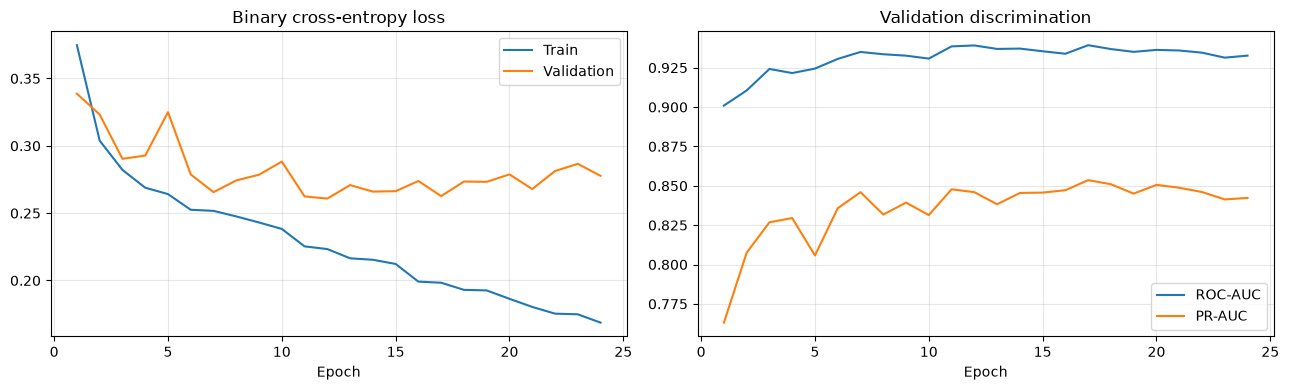

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], label="Validation")
axes[0].set_title("Binary cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(history_df["epoch"], history_df["validation_roc_auc"], label="ROC-AUC")
axes[1].plot(history_df["epoch"], history_df["validation_pr_auc"], label="PR-AUC")
axes[1].set_title("Validation discrimination")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 7: Validation threshold selection and test evaluation

In [9]:
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])

val_prob, val_true, _ = predict_loader(val_loader)
threshold_rows = []
for threshold in np.linspace(0.10, 0.90, 81):
    val_pred = (val_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": float(threshold),
        "f1": f1_score(val_true, val_pred, zero_division=0),
        "sensitivity": recall_score(val_true, val_pred, zero_division=0),
        "specificity": recall_score(val_true, val_pred, pos_label=0, zero_division=0),
    })
threshold_df = pd.DataFrame(threshold_rows)
best_threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])
print("Validation-selected threshold:", best_threshold)
display(threshold_df.sort_values("f1", ascending=False).head(10))

test_prob, test_true, test_loss = predict_loader(test_loader)
test_pred = (test_prob >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(test_true, test_pred, labels=[0, 1]).ravel()
metrics: dict[str, Any] = {
    "threshold": best_threshold,
    "test_loss": float(test_loss),
    "accuracy": float(accuracy_score(test_true, test_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(test_true, test_pred)),
    "precision": float(precision_score(test_true, test_pred, zero_division=0)),
    "sensitivity_recall": float(recall_score(test_true, test_pred, zero_division=0)),
    "specificity": float(tn / (tn + fp)) if tn + fp else float("nan"),
    "f1": float(f1_score(test_true, test_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(test_true, test_prob)),
    "pr_auc_average_precision": float(average_precision_score(test_true, test_prob)),
    "mcc": float(matthews_corrcoef(test_true, test_pred)),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}
display(pd.Series(metrics, name="test_value").to_frame())
print(classification_report(
    test_true, test_pred, target_names=["Non-MI", "MI"], zero_division=0
))

Validation-selected threshold: 0.36


,threshold,f1,sensitivity,specificity
26,0.36,0.768657,0.790787,0.916366
21,0.31,0.768402,0.821497,0.900722
20,0.30,0.767172,0.825336,0.897714
27,0.37,0.765918,0.785029,0.916968
19,0.29,0.764862,0.827255,0.894705
24,0.34,0.764706,0.798464,0.909146
18,0.28,0.764602,0.829175,0.893502
15,0.25,0.764553,0.844530,0.885680
23,0.33,0.763038,0.800384,0.906739
22,0.32,0.762943,0.806142,0.903730


,test_value
threshold,0.360000
test_loss,0.271984
accuracy,0.876706
balanced_accuracy,0.837422
precision,0.737705
sensitivity_recall,0.761278
specificity,0.913565
f1,0.749306
roc_auc,0.935240
pr_auc_average_precision,0.850010


              precision    recall  f1-score   support

      Non-MI       0.92      0.91      0.92      1666
          MI       0.74      0.76      0.75       532

    accuracy                           0.88      2198
   macro avg       0.83      0.84      0.83      2198
weighted avg       0.88      0.88      0.88      2198



## Step 8: Confusion matrix and ROC/PR curves

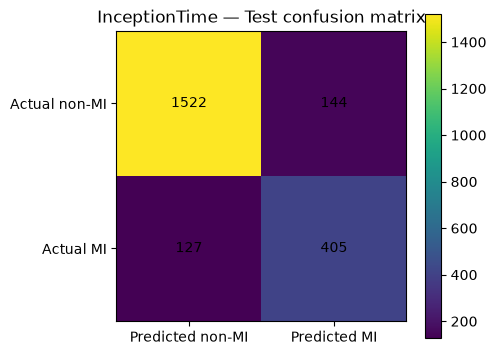

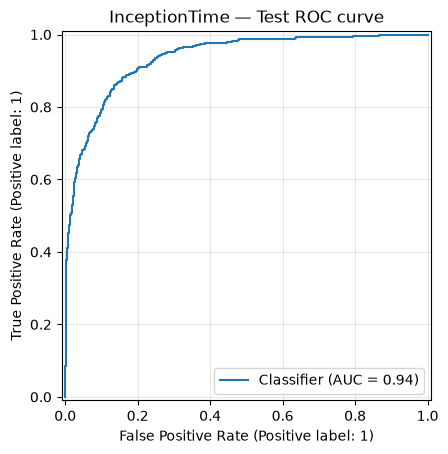

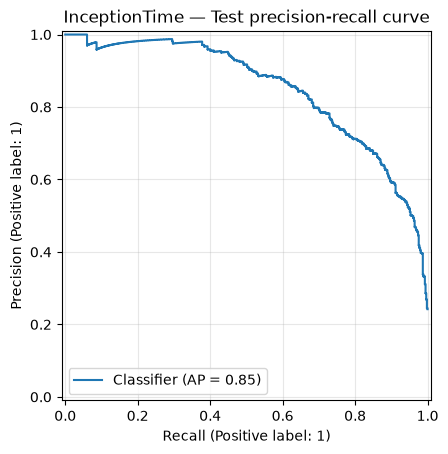

In [10]:
cm = confusion_matrix(test_true, test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm)
ax.set_xticks([0, 1], labels=["Predicted non-MI", "Predicted MI"])
ax.set_yticks([0, 1], labels=["Actual non-MI", "Actual MI"])
ax.set_title("InceptionTime — Test confusion matrix")
for (row, col), value in np.ndenumerate(cm):
    ax.text(col, row, str(value), ha="center", va="center")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(test_true, test_prob)
plt.title("InceptionTime — Test ROC curve")
plt.grid(alpha=0.3)
plt.show()

PrecisionRecallDisplay.from_predictions(test_true, test_prob)
plt.title("InceptionTime — Test precision-recall curve")
plt.grid(alpha=0.3)
plt.show()

## Step 9: Save metrics and experiment metadata

In [11]:
history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)
threshold_df.to_csv(RESULTS_DIR / "validation_threshold_search.csv", index=False)
with (RESULTS_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

metadata = {
    "model": "InceptionTime1D",
    "seed": SEED,
    "best_epoch": best_epoch,
    "best_validation_roc_auc": float(best_val_auc),
    "threshold_selection": "maximum validation F1",
    "sampling_rate_hz": FS,
    "input_shape_channels_first": [N_LEADS, N_SAMPLES],
    "train_records": len(train_df),
    "validation_records": len(val_df),
    "test_records": len(test_df),
    "patient_level_split_checks_passed": True,
}
with (RESULTS_DIR / "experiment_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)
print("Saved results to:", RESULTS_DIR)

Saved results to: c:\Users\sintu\Desktop\Myocardial Infarction\results\inceptiontime
